# Assignment 4: Machine Learning Model Application & Evaluation

## 1. Problem Definition
Dataset: The Breast Cancer Wisconsin (Diagnostic) dataset (UCI Machine Learning Repository) contains 569 patients. For each patient, 30 numeric measurements were computed from a digitized image of a fine needle aspirate (FNA) of a breast mass. They describe the cell nuclei (radius, texture, perimeter, area, smoothness, concavity, etc.).

Problem: Predict whether a tumor is Malignant (cancer) or Benign (not cancer).

- Features (X): 30 numeric columns (e.g. radius_mean, texture_mean, area_worst)
- Target (y): diagnosis (1 = Malignant, 0 = Benign)
- Problem type: Binary Classification

In [1]:
import glob
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score, ConfusionMatrixDisplay,
                             classification_report)

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
print("Libraries imported successfully")

Libraries imported successfully


In [2]:
files = glob.glob("/kaggle/input/**/*.csv", recursive=True) + glob.glob("*.csv")
files = [f for f in files if "submission" not in f.lower()]
print("CSV files found:", files)

df = None
for f in files:
    temp = pd.read_csv(f)
    if "diagnosis" in temp.columns:          # correct Kaggle file
        df = temp
        print("Using file:", f)
        break

if df is not None:
    # Remove unnecessary columns (only if they exist)
    df = df.drop(columns=[c for c in ["id", "Unnamed: 32"] if c in df.columns])
    # M = Malignant = 1 (positive case), B = Benign = 0
    df["diagnosis"] = df["diagnosis"].map({"M": 1, "B": 0})
else:
    print("No uploaded file found. Loading dataset from scikit-learn instead.")
    from sklearn.datasets import load_breast_cancer
    data = load_breast_cancer(as_frame=True)
    df = data.frame.copy()
    df["diagnosis"] = 1 - df["target"]       # make Malignant = 1
    df = df.drop(columns="target")

print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print(df["diagnosis"].value_counts())
df.head()

CSV files found: ['/kaggle/input/datasets/uciml/breast-cancer-wisconsin-data/data.csv', '/kaggle/input/datasets/muskanrafaqat/breast-cancer-wisconsin-diagnostic/data.csv']
Using file: /kaggle/input/datasets/uciml/breast-cancer-wisconsin-data/data.csv
Shape: (569, 31)
Missing values: 0
diagnosis
0    357
1    212
Name: count, dtype: int64


,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,1,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,1,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,1,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


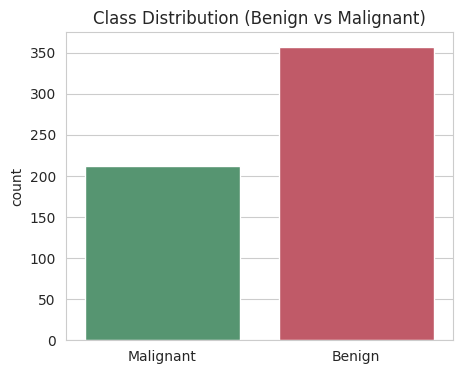

In [3]:
labels = df["diagnosis"].map({0: "Benign", 1: "Malignant"})
plt.figure(figsize=(5, 4))
sns.countplot(x=labels, hue=labels, palette=["#4C9F70", "#D1495B"], legend=False)
plt.title("Class Distribution (Benign vs Malignant)")
plt.xlabel("")
plt.show()

In [4]:
X = df.drop("diagnosis", axis=1)
y = df["diagnosis"]

# 80% training, 20% testing (stratify keeps the same class ratio in both sets)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# Scaling for Logistic Regression and KNN (fit on training data only)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print("Training set:", X_train.shape)
print("Testing set :", X_test.shape)

Training set: (455, 30)
Testing set : (114, 30)


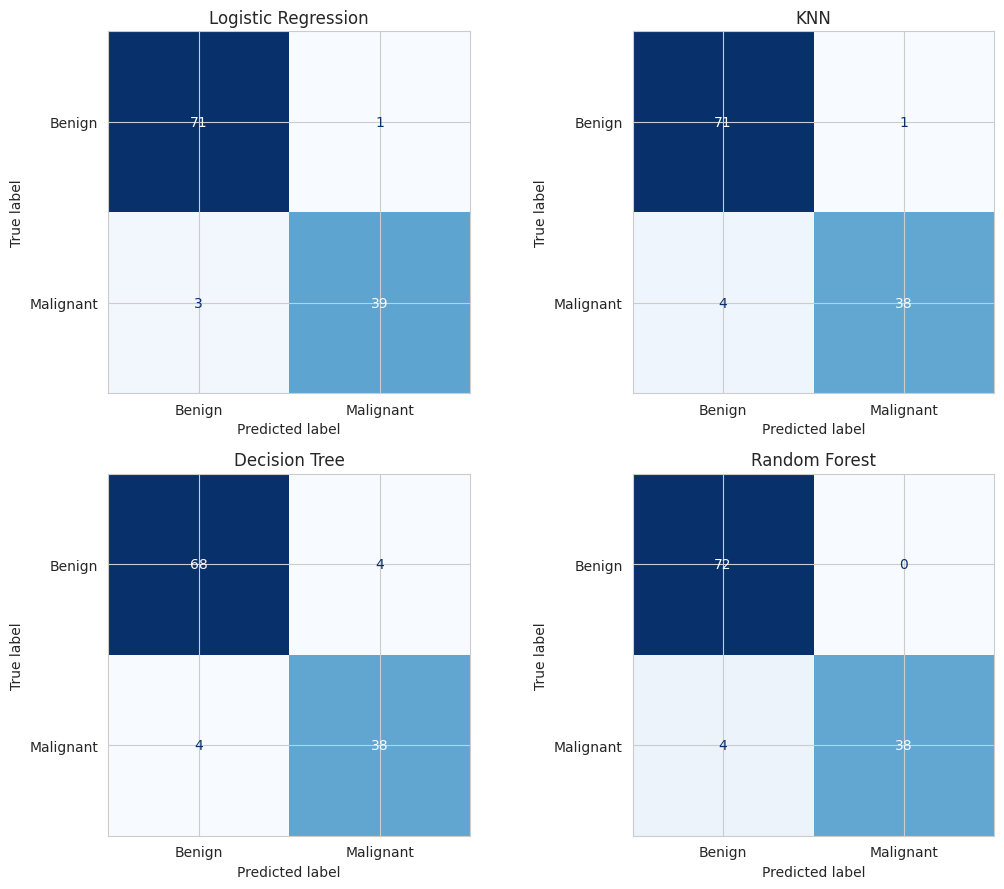

In [5]:
models = {
    "Logistic Regression": (LogisticRegression(max_iter=1000, random_state=42), True),
    "KNN": (KNeighborsClassifier(n_neighbors=5), True),
    "Decision Tree": (DecisionTreeClassifier(random_state=42), False),
    "Random Forest": (RandomForestClassifier(n_estimators=200, random_state=42), False),
}

results = []
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
axes = axes.ravel()

for ax, (name, (model, scaled)) in zip(axes, models.items()):
    Xtr = X_train_s if scaled else X_train
    Xte = X_test_s if scaled else X_test

    model.fit(Xtr, y_train)              # train on training data only
    pred = model.predict(Xte)            # predict on unseen test data
    cm = confusion_matrix(y_test, pred)

    ConfusionMatrixDisplay(cm, display_labels=["Benign", "Malignant"]).plot(
        ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)

    cv_recall = cross_val_score(model, Xtr, y_train, cv=5, scoring="recall").mean()

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "Train Accuracy": accuracy_score(y_train, model.predict(Xtr)),
        "CV Recall (5-fold)": cv_recall,
        "False Negatives": int(cm[1, 0]),
        "False Positives": int(cm[0, 1]),
    })

plt.tight_layout()
plt.show()

In [6]:
for name, (model, scaled) in models.items():
    Xte = X_test_s if scaled else X_test
    print("=" * 55)
    print(name)
    print(classification_report(y_test, model.predict(Xte),
                                target_names=["Benign", "Malignant"]))

Logistic Regression
              precision    recall  f1-score   support

      Benign       0.96      0.99      0.97        72
   Malignant       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114

KNN
              precision    recall  f1-score   support

      Benign       0.95      0.99      0.97        72
   Malignant       0.97      0.90      0.94        42

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114

Decision Tree
              precision    recall  f1-score   support

      Benign       0.94      0.94      0.94        72
   Malignant       0.90      0.90      0.90        42

    accuracy                           0.93       114
   macro avg       0.92      0.92      0.92       114
weighted avg       0.93      0.93   

In [7]:
results_df = pd.DataFrame(results).round(3)
results_df

,Model,Accuracy,Precision,Recall,F1,Train Accuracy,CV Recall (5-fold),False Negatives,False Positives
0,Logistic Regression,0.965,0.975,0.929,0.951,0.987,0.947,3,1
1,KNN,0.956,0.974,0.905,0.938,0.978,0.918,4,1
2,Decision Tree,0.930,0.905,0.905,0.905,1.000,0.912,4,4
3,Random Forest,0.965,1.000,0.905,0.950,1.000,0.935,4,0


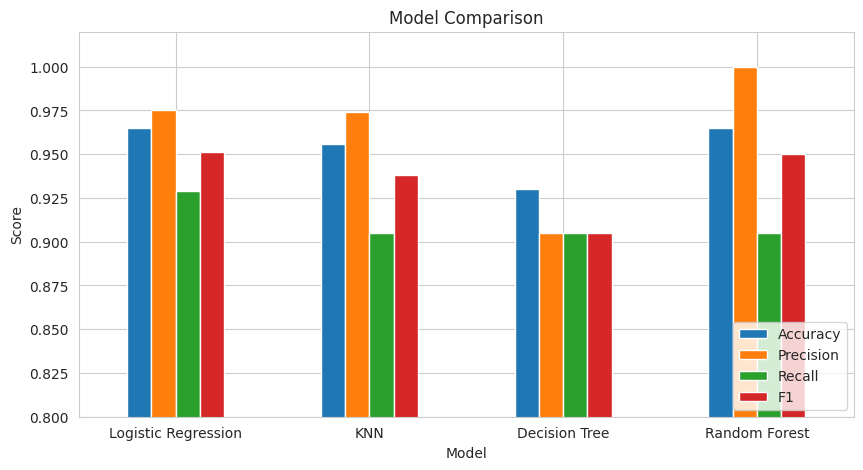

In [8]:
results_df.set_index("Model")[["Accuracy", "Precision", "Recall", "F1"]].plot(
    kind="bar", figsize=(10, 5), ylim=(0.8, 1.02), rot=0)
plt.title("Model Comparison")
plt.ylabel("Score")
plt.legend(loc="lower right")
plt.show()

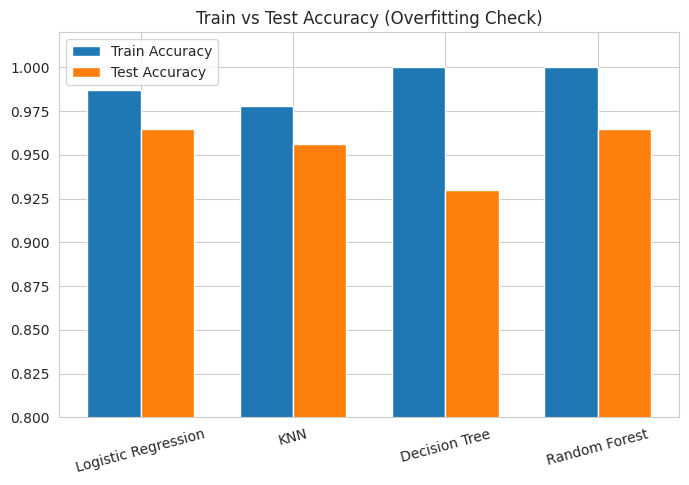

In [9]:
x = np.arange(len(results_df))
w = 0.35
plt.figure(figsize=(8, 5))
plt.bar(x - w/2, results_df["Train Accuracy"], w, label="Train Accuracy")
plt.bar(x + w/2, results_df["Accuracy"], w, label="Test Accuracy")
plt.xticks(x, results_df["Model"], rotation=15)
plt.ylim(0.8, 1.02)
plt.title("Train vs Test Accuracy (Overfitting Check)")
plt.legend()
plt.show()

In [10]:
best = results_df.sort_values(["Recall", "F1"], ascending=False).iloc[0]
results_df["Overfit Gap"] = (results_df["Train Accuracy"] - results_df["Accuracy"]).round(3)

print("Best model (by Recall, then F1):", best["Model"])
print("Recall   :", best["Recall"])
print("F1-score :", best["F1"])
print("Accuracy :", best["Accuracy"])
print("Cancer cases missed (False Negatives):", int(best["False Negatives"]))
print()
print(results_df[["Model", "Train Accuracy", "Accuracy", "Overfit Gap"]].to_string(index=False))

Best model (by Recall, then F1): Logistic Regression
Recall   : 0.929
F1-score : 0.951
Accuracy : 0.965
Cancer cases missed (False Negatives): 3

              Model  Train Accuracy  Accuracy  Overfit Gap
Logistic Regression           0.987     0.965        0.022
                KNN           0.978     0.956        0.022
      Decision Tree           1.000     0.930        0.070
      Random Forest           1.000     0.965        0.035


## Final Conclusion

1. Which model performed best?
Logistic Regression performed best. It had the highest Recall (0.929) and the fewest False Negatives (3), with a high Precision (0.975) and F1-score (0.951). Random Forest had the same Accuracy but missed more cancer cases.

2. Which metric was mainly used to make this decision?
Recall, with F1-score used as a tie-breaker. Accuracy alone was not used, because it can hide dangerous mistakes.

3. Why is this metric important for this problem?
In cancer detection, a False Negative means a malignant tumor is predicted as benign, so the patient may not get treatment on time. This is much more serious than a False Positive, which only leads to extra tests. Therefore Recall (catching as many malignant cases as possible) matters more than raw Accuracy.

4. Is the model showing any signs of overfitting or underfitting?
Decision Tree and Random Forest reach 100% training accuracy but lower test accuracy (93% and 96.5%), which shows overfitting, strongest in the Decision Tree. Logistic Regression has training accuracy (98.7%) and test accuracy (96.5%) close together, so it is well balanced. No model shows underfitting, because all models score high on both training and test data.

Limitation: the test set is small (114 patients), so one or two predictions can change the scores.